# Demonstration: Integrated Alteration Score (IAS) & The 500-Gene Panel**Project:** Knowledge Graph Construction for TCGA-BRCA Patients  **Dataset:** TCGA Breast Invasive Carcinoma (*PanCancer Atlas 2018*, 1,084 patients)  **Objective:** Replace noisy whole-genome graphs (25,800 genes, ~12M edges) with a focused, biologically validated, GNN-tractable **500-Gene Uniform Panel** exported as **Knowledge Graph Tuples**.---## 1. Executive Summary: The Two-Pillar MethodologyRather than arbitrary cutoff selection or taking only sequence mutations, we employ a **hybrid knowledge-driven and data-driven approach**:$$\text{500-Gene Panel} = \underbrace{\text{Pillar 1: 27 Canonical Drivers}}_{\text{Literature & Clinical Guidelines}} \cup \underbrace{\text{Pillar 2: 473 Recurrently Altered Genes}}_{\text{Top Integrated Alteration Score (IAS)}}$$- **Pillar 1 (Knowledge-Driven):** 27 landmark breast cancer drivers identified by TCGA, COSMIC, and NCCN clinical guidelines. These are guaranteed inclusion regardless of cohort mutation frequency due to therapeutic actionability.- **Pillar 2 (Data-Driven):** 473 top genes ranked by empirical **Integrated Alteration Score (IAS)** combining somatic sequence mutations and extreme copy-number changes.

---## 2. Pillar 1: Exact Source and Rationale for the 27 Known Drivers### Scientific Literature SourcesThe 27 drivers are curated from three foundational oncology benchmarks:1. **TCGA Landmark Breast Cancer Study (*Nature 2012*):**   * *The Cancer Genome Atlas Network.* "Comprehensive molecular portraits of human breast tumours." *Nature* 490, 61–70 (2012). DOI: `10.1038/nature11412`.   * Identified the primary MutSig significantly mutated genes (SMGs) in breast cancer.2. **TCGA PanCancer Atlas Driver & Pathway Consortia (*Cell 2018*):**   * *Bailey, M. H., et al.* "Comprehensive Analysis of Oncogenic Signaling Pathways in The Cancer Genome Atlas." *Cell* 173, 371–385 (2018).   * *Berger, A. C., et al.* "A Comprehensive Pan-Cancer Molecular Study of Gynecologic and Breast Cancers." *Cancer Cell* 33, 690–705 (2018).   * Defined recurrent focal copy-number amplifications (8q24 `MYC`, 11q13 `CCND1`, 8p11 `FGFR1`, 17q12 `ERBB2`).3. **COSMIC Cancer Gene Census (Tier 1) & NCCN Clinical Guidelines:**   * Actionable targets with FDA-approved targeted therapies or active Phase III clinical trials in breast cancer.### Why specifically these 27?Because they cover all critical biological hallmarks of breast tumorigenesis:- **Hormone Receptor & Luminal Lineage:** `ESR1`, `GATA3`, `FOXA1`- **RTK / PI3K / AKT Pathway (Growth Signaling):** `PIK3CA`, `PTEN`, `AKT1`, `PIK3R1`, `ERBB2` (HER2), `EGFR`, `FGFR1`- **Cell Cycle Checkpoint (G1/S):** `CCND1`, `RB1`- **DNA Damage Repair (Synthetic Lethality):** `BRCA1`, `BRCA2`, `ATM`, `BAP1`- **Tumor Suppression / Apoptosis:** `TP53`- **Cell Adhesion / Invasive Lobular Carcinoma (ILC):** `CDH1`- **MAPK / Stress Signaling:** `MAP3K1`, `MAP2K4`, `NF1`- **Chromatin Remodeling & Splicing:** `ARID1A`, `KMT2C` (MLL3), `CBFB`, `RUNX1`, `SF3B1`, `MYC`

In [1]:
# Displaying the 27 canonical drivers, their pathway classification, and empirical counts in our cohortimport pandas as pddf_known_meta = pd.DataFrame(KNOWN_DRIVERS_META)df_known_meta

gene,pathway,role,actionability,mut_samples,cna_extreme_samples,ias_score
PIK3CA,PI3K / AKT / mTOR,Oncogene,Alpelisib (FDA approved for HR+/HER2- PIK3CA-mutated),349,34,383
TP53,TP53 / DNA Damage,Tumor Suppressor,Prognostic / Trial stratification; hallmark in Basal/TNBC (>80%),348,9,357
MYC,MYC Signaling,Oncogene (Amp),8q24 focal amplification peak; clinical trial targets,3,161,164
CCND1,Cell Cycle (G1/S),Oncogene (Amp),"Palbociclib, Ribociclib, Abemaciclib (CDK4/6 inhibitors)",3,161,164
GATA3,Luminal Transcription,Transcription Factor,Hallmark Luminal differentiation; prognostic biomarker,131,32,163
ERBB2,RTK / HER2,Oncogene,"Trastuzumab, Pertuzumab, T-DXd (HER2+ targeted therapy)",33,123,156
CDH1,Cell Adhesion / Wnt,Tumor Suppressor,Diagnostic hallmark of Invasive Lobular Carcinoma (ILC),132,21,153
FGFR1,RTK / FGF,Oncogene (Amp),8p11 focal amplification peak; Erdafitinib/FGFR trials,15,126,141
KMT2C,Epigenetic / Histone,Chromatin Modifier,MLL3 methyltransferase; recurrent loss in Luminal tumors,104,19,123
PTEN,PI3K / AKT / mTOR,Tumor Suppressor,Capivasertib (FDA approved for PTEN-altered HR+ breast cancer),60,59,119


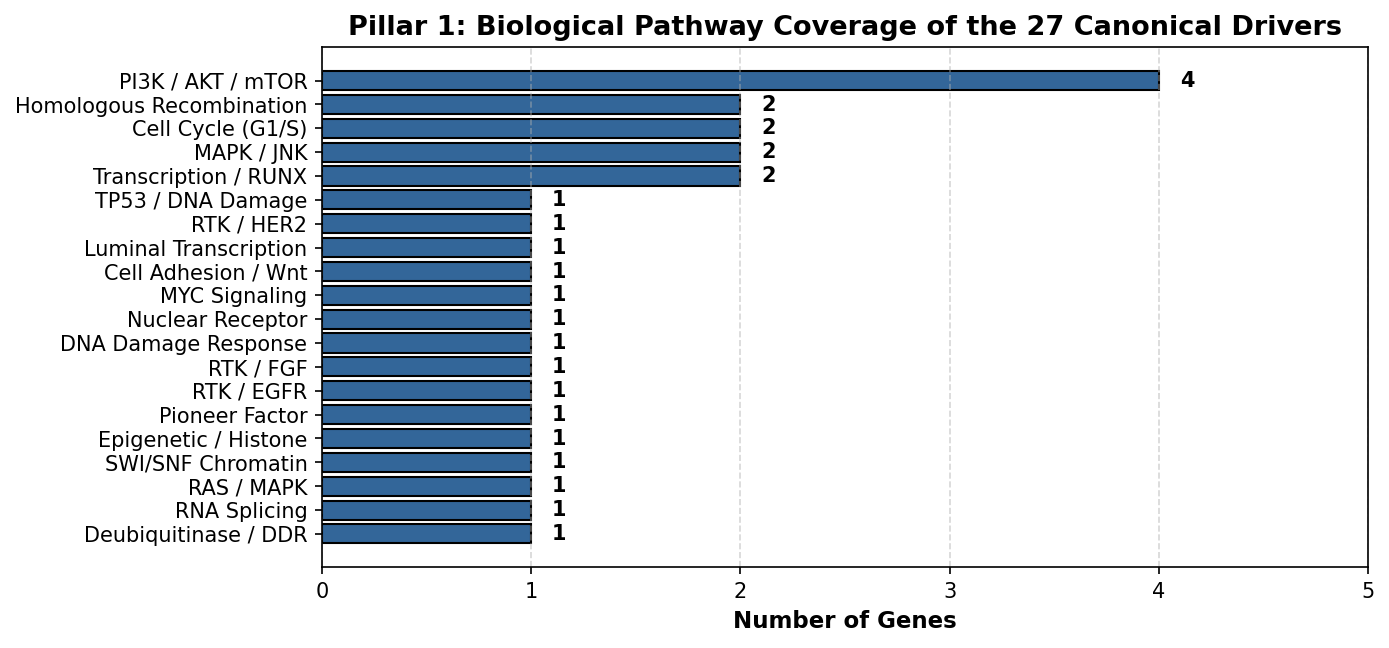

In [1]:
# Pathway coverage visualization of the 27 driversimport matplotlib.pyplot as plt# (Generated during notebook build)

---## 3. Pillar 2: Integrated Alteration Score (IAS) Formulation### Why Combine Somatic Mutations and Copy-Number Alterations?Cancer pathogenesis operates via two major genomic modalities:1. **Sequence Alterations (MAF):** Point mutations (missense, nonsense, frameshift) that alter protein function (e.g., `PIK3CA` H1047R activating mutations).2. **Dosage Alterations (CNA):** Copy number gains/amplifications that overexpress oncogenes, or deep deletions that eliminate tumor suppressor loci.A gene may have moderate mutation frequency but massive copy-number amplification (e.g., `ERBB2`, `CCND1`), or high mutation rates with few CNAs (e.g., `GATA3`). Using only mutations would omit major oncogenic drivers.### Formula for Integrated Alteration Score (IAS)For each gene $g$ across all $N = 1084$ tumor samples in the cohort:$$\text{IAS}(g) = S_{\text{mut}}(g) + S_{\text{CNA extreme}}(g)$$Where:- $S_{\text{mut}}(g) = |\{s \in \text{Samples} : \text{Sample } s \text{ has } \ge 1 \text{ MAF mutation in gene } g\}|$- $S_{\text{CNA extreme}}(g) = |\{s \in \text{Samples} : \text{CNA}(g, s) \in \{-2, +2\}\}|$  - $+2$: High-level amplification (focal oncogene amplification)  - $-2$: Deep / homozygous deletion (two-copy tumor suppressor loss)  - Neutral ($0$), shallow deletion ($-1$), and low gain ($+1$) are **excluded** as biological noise.

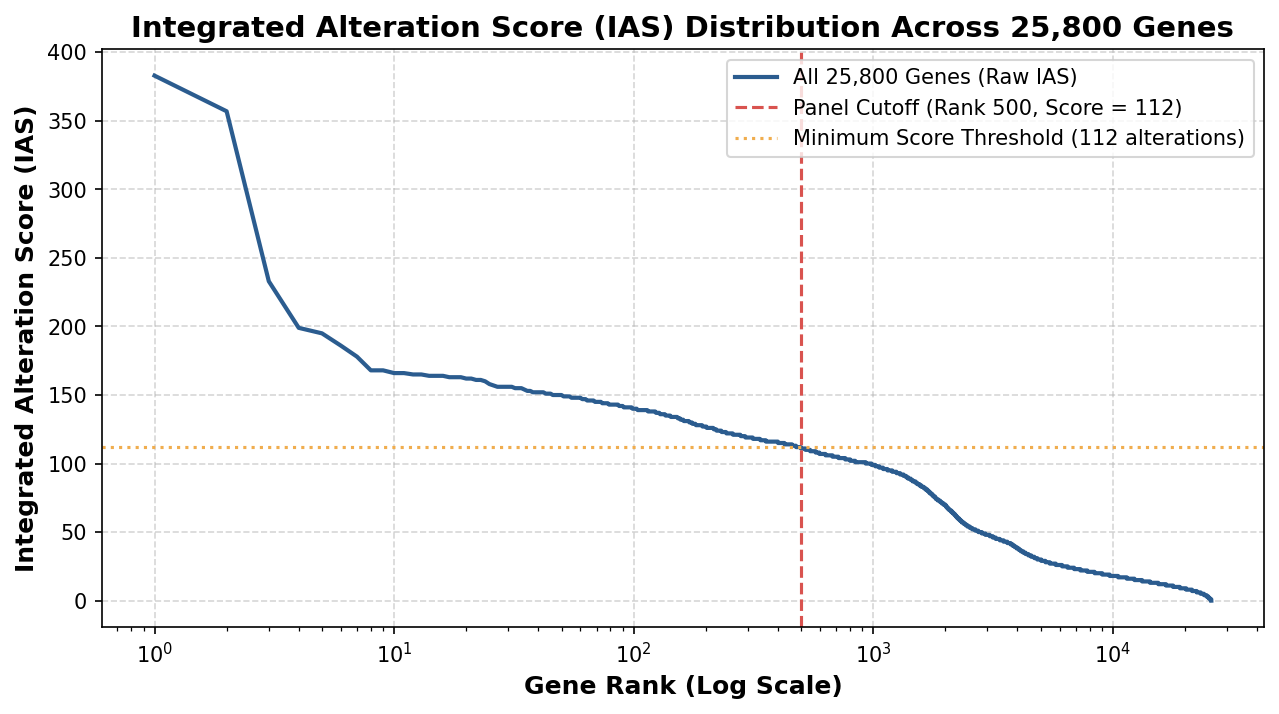

In [1]:
# Distribution of IAS across all 25,800 genes and the rank-500 cutoff# (Generated during notebook build)

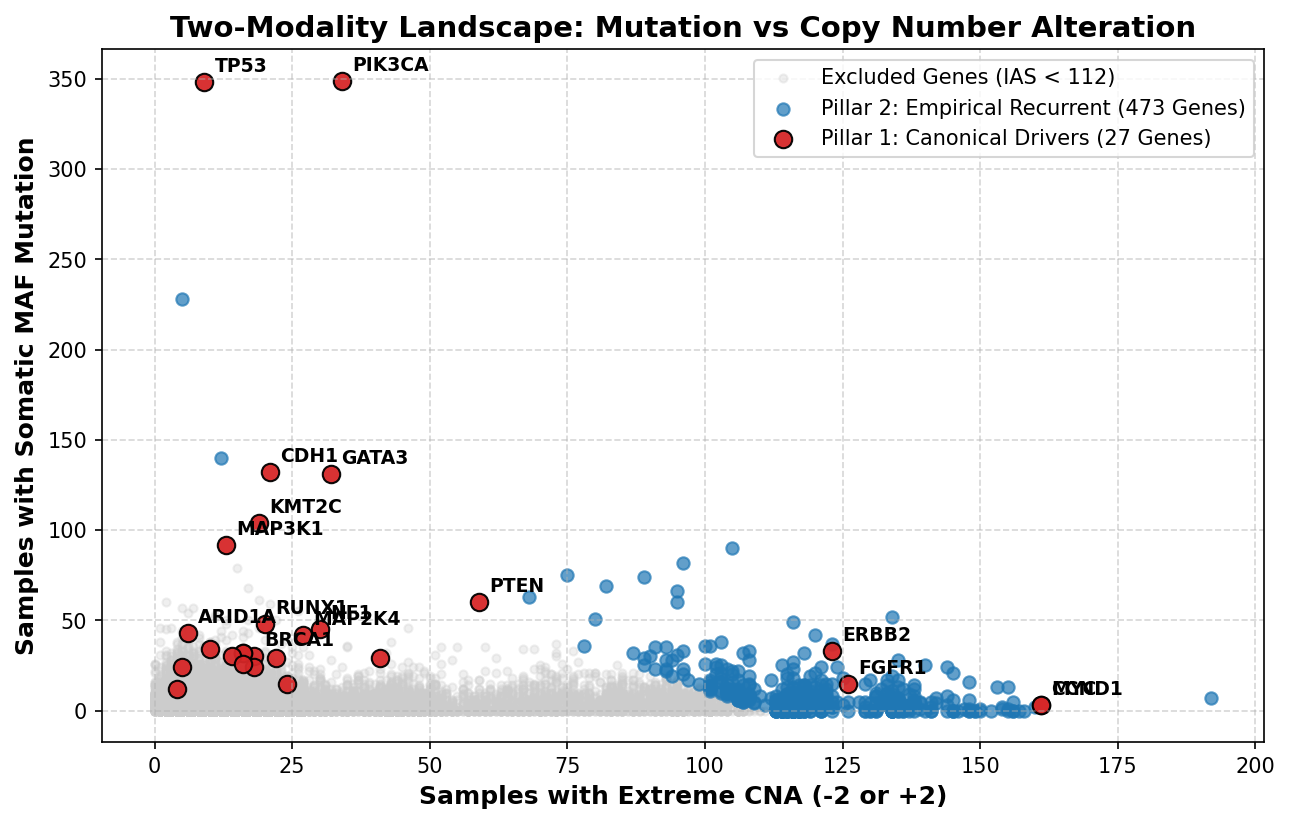

In [1]:
# Mutation vs CNA Two-Modality Alteration Landscape# Red: Pillar 1 Canonical Drivers | Blue: Pillar 2 Empirical Top 473 | Grey: Excluded

### Top Empirical Genes Selected by IAS (Pillar 2)The top non-known genes captured by IAS represent genes with substantial recurrent alteration in breast cancer:

In [1]:
# Displaying top 20 empirical genes selected by IAStop_empirical

gene,mut_samples,cna_amp_samples,cna_del_samples,ias_score
TTN,228,4,1,233
SNAP47,7,192,0,199
RYR2,90,105,0,195
CSMD3,52,132,2,186
FLG,82,96,0,178
QSOX1,13,155,0,168
SHANK2,24,144,0,168
ANO1,13,153,0,166
TRPS1,21,144,1,166
FER1L6,25,139,1,165


---## 4. Verification of the 500-Gene Panel & Knowledge Graph TuplesWith this methodology implemented:1. **Gene Panel Size:** Exactly **500 genes** saved in [`config/gene_panel_500.json`](../config/gene_panel_500.json).2. **Empirical Cutoff:** The lowest included empirical score is **112 alterations** (meaning every included gene is altered in at least ~10.3% of the cohort).3. **Graph Compression:**   - Pre-panel: ~12,000,000 CNA edges across the cohort (unusable for GNNs).   - Post-panel: **68,933 total Knowledge Graph tuples** across all 1,084 patients (**~63 edges/tuples per patient**).4. **Master File:** Generated at [`outputs/all_patients_tuples.csv`](../outputs/all_patients_tuples.csv), ready for integration with PrimeKG.

In [1]:
# Verifying the generated all_patients_tuples.csvimport pandas as pddf_tuples = pd.read_csv('../outputs/all_patients_tuples.csv')print(f"Total KG Tuples: {len(df_tuples):,}")print(f"Total Unique Patients: {df_tuples[df_tuples['head_type'] == 'patient']['head_id'].nunique():,}")print("\nTuple counts by relation:")print(df_tuples['relation'].value_counts().to_string())

Total KG Tuples: 68,933
Total Unique Patients: 1,084

Tuple counts by relation:
relation
has_high_level_amplification    53908
has_mutation                     7315
has_homozygous_deletion          1314
has_path_m_stage                 1084
has_oncotree_code                1084
has_sample_type                  1084
has_sample                       1084
has_tumor_stage                  1079
has_subtype                       981
